In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
from pathlib import Path
import gc
import json
import math
import random
import time
import warnings

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from IPython.display import display

SEED = 42
BACKBONES = ["densenet121", "resnet50", "efficientnet_b0"]
LABELS = ["Effusion", "Cardiomegaly", "Pneumothorax", "Atelectasis",
          "Consolidation", "Mass", "Nodule"]

IMAGE_SIZE = 224
NUM_WORKERS = 2
EVAL_BATCH_SIZE = 64
MIN_POS = 10

# Follow the supplied tuning notebook's final-retraining sample sizes.
FINAL_TRAIN_SIZE = 40_000
FINAL_VAL_SIZE = 8_000
TRAIN_DIAGNOSTIC_SIZE = 2_000
FINAL_EPOCHS = 8

# Stability settings retained from the tuning notebook.
WARMUP_FRAC = 0.05
GRAD_CLIP_NORM = 1.0
USE_IMAGENET_WEIGHTS = True

PREPROCESSED_ROOT = Path("/kaggle/input/notebooks/t1f3001843/dsai-nih-preprocessing")
# Point this at the tuning notebook output folder (or attached Kaggle dataset).
TUNING_RESULTS_ROOT = Path("/kaggle/input/notebooks/t1f3001843/dsai-nih-hyperparameter/nih_multi_backbone_tuning")
OUTPUT_DIR = Path("/kaggle/working/nih_generalization_experiments")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Optional fallback. Populate only if best_config.json files cannot be loaded.
# Values must come from your completed NIH hyperparameter tuning results.
MANUAL_BEST_CONFIGS = {
    # "densenet121": {"learning_rate": ..., "batch_size": ..., "dropout": ..., "weight_decay": ...},
    # "resnet50": {"learning_rate": ..., "batch_size": ..., "dropout": ..., "weight_decay": ...},
    # "efficientnet_b0": {"learning_rate": ..., "batch_size": ..., "dropout": ..., "weight_decay": ...},
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

Device: cuda
GPU: Tesla T4


In [3]:
REQUIRED_CONFIG_KEYS = {"learning_rate", "batch_size", "dropout", "weight_decay"}

def load_best_configs():
    configs = {}
    for backbone in BACKBONES:
        path = TUNING_RESULTS_ROOT / backbone / "best_config.json"
        if path.exists():
            cfg = json.loads(path.read_text())
        elif backbone in MANUAL_BEST_CONFIGS:
            cfg = dict(MANUAL_BEST_CONFIGS[backbone])
        else:
            raise FileNotFoundError(
                f"Missing {path}. Attach the tuning output as a Kaggle input, "
                "correct TUNING_RESULTS_ROOT, or populate MANUAL_BEST_CONFIGS."
            )
        missing = REQUIRED_CONFIG_KEYS - set(cfg)
        if missing:
            raise ValueError(f"{backbone} config missing keys: {sorted(missing)}")
        cfg["learning_rate"] = float(cfg["learning_rate"])
        cfg["batch_size"] = int(cfg["batch_size"])
        cfg["dropout"] = float(cfg["dropout"])
        cfg["weight_decay"] = float(cfg["weight_decay"])
        configs[backbone] = cfg
    return configs

BEST_CONFIGS = load_best_configs()
display(pd.DataFrame(BEST_CONFIGS).T)

,learning_rate,batch_size,dropout,weight_decay
densenet121,0.000296,32.0,0.2,0.002659
resnet50,0.000228,32.0,0.2,0.051632
efficientnet_b0,0.000395,32.0,0.2,0.001494


In [4]:
manifest_path = PREPROCESSED_ROOT / "outputs/processed/nih_full_manifest.csv"
if not manifest_path.exists():
    candidates = list(PREPROCESSED_ROOT.rglob("nih_full_manifest.csv"))
    if not candidates:
        raise FileNotFoundError(f"Could not find nih_full_manifest.csv under {PREPROCESSED_ROOT}")
    manifest_path = candidates[0]

print("Manifest:", manifest_path)
manifest = pd.read_csv(manifest_path)

required_columns = {"official_split", "patient_id", "shard_index", "shard_path", *LABELS}
missing_columns = required_columns - set(manifest.columns)
if missing_columns:
    raise ValueError(f"Manifest is missing columns: {sorted(missing_columns)}")

# Resolve shard paths using the same relative-path strategy as the supplied notebook.
shard_files_by_key = {}
for path in PREPROCESSED_ROOT.rglob("*.npy"):
    shard_files_by_key[path.parts[-3:]] = path

def resolve_shard_path(value):
    candidate = Path(str(value))
    if candidate.is_file():
        return str(candidate)
    match = shard_files_by_key.get(candidate.parts[-3:])
    return str(match) if match is not None else None

manifest["shard_path"] = manifest["shard_path"].map(resolve_shard_path)
if manifest["shard_path"].isna().any():
    raise FileNotFoundError(f"Could not resolve {manifest['shard_path'].isna().sum():,} manifest rows to .npy shards.")

manifest["shard_index"] = pd.to_numeric(manifest["shard_index"], errors="coerce")
if manifest["shard_index"].isna().any():
    raise ValueError("Some rows have missing/non-numeric shard_index.")
manifest["shard_index"] = manifest["shard_index"].astype(int)
manifest["official_split"] = manifest["official_split"].astype(str).str.lower()
manifest["patient_id"] = manifest["patient_id"].astype(str)

for label in LABELS:
    if not manifest[label].isin([0, 1]).all():
        raise ValueError(f"Label {label} contains values other than 0/1.")

train_all = manifest[manifest["official_split"].eq("train_val")].copy()
test_data = manifest[manifest["official_split"].eq("test")].reset_index(drop=True)
if train_all.empty or test_data.empty:
    raise ValueError(f"Expected non-empty train_val and test splits. Found {manifest['official_split'].value_counts().to_dict()}")

RARE_FIRST = train_all[LABELS].sum().sort_values().index.tolist()

def make_strata(df):
    pos = np.column_stack([df[c].eq(1).to_numpy() for c in RARE_FIRST])
    return np.where(pos.any(axis=1), pos.argmax(axis=1), len(RARE_FIRST))

sgkf = StratifiedGroupKFold(n_splits=9, shuffle=True, random_state=SEED)
train_idx, val_idx = next(sgkf.split(train_all, make_strata(train_all), groups=train_all["patient_id"]))
train_data = train_all.iloc[train_idx].reset_index(drop=True)
val_data = train_all.iloc[val_idx].reset_index(drop=True)

assert set(train_data.patient_id).isdisjoint(set(val_data.patient_id))
assert set(train_data.patient_id).isdisjoint(set(test_data.patient_id))
assert set(val_data.patient_id).isdisjoint(set(test_data.patient_id))

for df in (train_data, val_data, test_data):
    for label in LABELS:
        df[label] = df[label].astype(np.float32)

def sample_frame(df, n):
    return df.sample(n=min(n, len(df)), random_state=SEED).reset_index(drop=True)

final_train = sample_frame(train_data, FINAL_TRAIN_SIZE)
final_val = sample_frame(val_data, FINAL_VAL_SIZE)
train_diagnostic = sample_frame(final_train, TRAIN_DIAGNOSTIC_SIZE)

print(f"Train: {len(final_train):,} images / {final_train.patient_id.nunique():,} patients")
print(f"Validation: {len(final_val):,} images / {final_val.patient_id.nunique():,} patients")
print(f"Train diagnostic subset: {len(train_diagnostic):,} images")
print(f"Official NIH test (held until final evaluation): {len(test_data):,} images / {test_data.patient_id.nunique():,} patients")

Manifest: /kaggle/input/notebooks/t1f3001843/dsai-nih-preprocessing/outputs/processed/nih_full_manifest.csv
Train: 22,319 images / 8,117 patients
Validation: 2,726 images / 1,010 patients
Train diagnostic subset: 2,000 images
Official NIH test (held until final evaluation): 11,778 images / 1,169 patients


In [5]:
class AddGaussianNoise:
    def __init__(self, std=0.02, p=0.5):
        self.std, self.p = std, p
    def __call__(self, x):
        if random.random() < self.p:
            x = x + torch.randn_like(x) * self.std
        return x.clamp(0.0, 1.0)

class NIHShardDataset(Dataset):
    MEAN, STD = 0.449, 0.226  # retained from supplied NIH tuning notebook

    def __init__(self, frame, setup="A", training=False):
        self.frame = frame.reset_index(drop=True)
        self.paths = self.frame["shard_path"].astype(str).to_numpy()
        self.positions = self.frame["shard_index"].astype(int).to_numpy()
        self.targets = self.frame[LABELS].to_numpy(dtype=np.float32)
        self.shard_cache = {}
        self.setup = setup
        self.training = training

        if not training or setup == "A":
            self.augmentation = None
        elif setup == "B":
            self.augmentation = transforms.Compose([
                transforms.RandomAffine(degrees=5, translate=(0.02, 0.02)),
                transforms.ColorJitter(contrast=0.05),
            ])
        elif setup in ("C", "D", "E"):
            ops = [
                transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
                transforms.ColorJitter(brightness=0.15, contrast=0.15),
            ]
            # Randomly choose mild noise or blur for each sample.
            ops.append(transforms.RandomChoice([
                AddGaussianNoise(std=0.02, p=1.0),
                transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.6)),
            ]))
            if setup == "E":
                ops.append(transforms.RandomErasing(p=0.25, scale=(0.01, 0.05),
                                                    ratio=(0.5, 2.0), value=0))
            self.augmentation = transforms.Compose(ops)
        else:
            raise ValueError(f"Unknown setup: {setup}")

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        path, pos = self.paths[index], int(self.positions[index])
        if path not in self.shard_cache:
            self.shard_cache[path] = np.load(path, mmap_mode="r", allow_pickle=False)
        shard = self.shard_cache[path]
        if not 0 <= pos < len(shard):
            raise IndexError(f"shard_index {pos} outside shard length {len(shard)}: {path}")
        image = np.asarray(shard[pos])
        if image.ndim != 2:
            raise ValueError(f"Expected grayscale (H,W), got {image.shape}")
        image = image.astype(np.float32)
        if shard.dtype == np.uint8:
            image /= 255.0
        image = torch.from_numpy(image.copy()).unsqueeze(0)
        if self.augmentation is not None:
            image = self.augmentation(image)
        image = (image - self.MEAN) / self.STD
        return image, torch.from_numpy(self.targets[index])

def make_loader(frame, batch_size, training=False, setup="A", shuffle=None):
    if shuffle is None:
        shuffle = training
    return DataLoader(
        NIHShardDataset(frame, setup=setup, training=training),
        batch_size=batch_size, shuffle=shuffle, num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(NUM_WORKERS > 0),
    )

# Inspect one sample and the label dimensionality.
sample_image, sample_target = NIHShardDataset(final_train, setup="A", training=False)[0]
print("Image tensor:", tuple(sample_image.shape), "| target shape:", tuple(sample_target.shape))
assert len(LABELS) == sample_target.numel()

Image tensor: (1, 224, 224) | target shape: (7,)


In [6]:
def adapt_first_conv_to_grayscale(old_conv):
    new_conv = nn.Conv2d(
        1, old_conv.out_channels, kernel_size=old_conv.kernel_size,
        stride=old_conv.stride, padding=old_conv.padding,
        dilation=old_conv.dilation, groups=old_conv.groups,
        bias=old_conv.bias is not None,
    )
    with torch.no_grad():
        new_conv.weight.copy_(old_conv.weight.mean(dim=1, keepdim=True))
        if old_conv.bias is not None:
            new_conv.bias.copy_(old_conv.bias)
    return new_conv

def build_model(backbone, dropout):
    n_out = len(LABELS)
    if backbone == "densenet121":
        weights = models.DenseNet121_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.densenet121(weights=weights)
        model.features.conv0 = adapt_first_conv_to_grayscale(model.features.conv0)
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier.in_features, n_out))
    elif backbone == "resnet50":
        weights = models.ResNet50_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.resnet50(weights=weights)
        model.conv1 = adapt_first_conv_to_grayscale(model.conv1)
        model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.fc.in_features, n_out))
    elif backbone == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.efficientnet_b0(weights=weights)
        model.features[0][0] = adapt_first_conv_to_grayscale(model.features[0][0])
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier[-1].in_features, n_out))
    else:
        raise ValueError(f"Unknown backbone: {backbone}")
    return model

def bce_loss(logits, targets):
    return nn.functional.binary_cross_entropy_with_logits(logits, targets)

def per_label_auroc(probs, targets):
    scores = {}
    for j, label in enumerate(LABELS):
        y = targets[:, j]
        if (y == 1).sum() < MIN_POS or (y == 0).sum() < MIN_POS:
            scores[label] = float("nan")
        else:
            scores[label] = float(roc_auc_score(y, probs[:, j]))
    return scores

def macro_auroc(scores):
    vals = np.asarray([v for v in scores.values() if np.isfinite(v)], dtype=float)
    return float(vals.mean()) if len(vals) else float("nan")

@torch.no_grad()
def evaluate(model, loader, return_raw=False):
    model.eval()
    losses, logits_all, targets_all = [], [], []
    with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        for images, targets in loader:
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(images)
            losses.append(float(bce_loss(logits.float(), targets).cpu()))
            logits_all.append(logits.float().cpu())
            targets_all.append(targets.cpu())
    logits = torch.cat(logits_all)
    targets = torch.cat(targets_all)
    probs = torch.sigmoid(logits).numpy()
    y = targets.numpy()
    scores = per_label_auroc(probs, y)
    result = {"loss": float(np.mean(losses)), "macro_auroc": macro_auroc(scores),
              "per_label_auroc": scores}
    if return_raw:
        result["probs"], result["targets"] = probs, y
    return result

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def mixup_batch(images, targets, alpha=0.2):
    if alpha <= 0:
        return images, targets
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(images.size(0), device=images.device)
    mixed_images = lam * images + (1.0 - lam) * images[index]
    mixed_targets = lam * targets + (1.0 - lam) * targets[index]
    return mixed_images, mixed_targets

In [7]:
def train_one_run(backbone, setup, config, epochs=FINAL_EPOCHS):
    run_dir = OUTPUT_DIR / backbone / setup
    run_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = run_dir / "best_checkpoint.pt"
    last_checkpoint_path = run_dir / "last_checkpoint.pt"

    set_seed(SEED)
    train_loader = make_loader(final_train, config["batch_size"], training=True, setup=setup)
    val_loader = make_loader(final_val, EVAL_BATCH_SIZE, training=False, setup="A", shuffle=False)
    train_eval_loader = make_loader(train_diagnostic, EVAL_BATCH_SIZE, training=False, setup="A", shuffle=False)

    model = build_model(backbone, config["dropout"]).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"]
    )
    total_steps = epochs * len(train_loader)
    warmup_steps = max(1, int(WARMUP_FRAC * total_steps))
    warmup = torch.optim.lr_scheduler.LinearLR(
        optimizer, start_factor=0.01, total_iters=warmup_steps
    )
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(1, total_steps - warmup_steps),
        eta_min=config["learning_rate"] * 0.05
    )
    scheduler = torch.optim.lr_scheduler.SequentialLR(
        optimizer, [warmup, cosine], milestones=[warmup_steps]
    )
    scaler = make_scaler()

    best_auc, best_val_loss, best_epoch = -np.inf, np.inf, None
    history = []

    try:
        for epoch in range(1, epochs + 1):
            model.train()
            t0 = time.perf_counter()
            batch_losses, preclip_norms = [], []
            clipped_batches = 0

            for images, targets in train_loader:
                images = images.to(DEVICE, non_blocking=True)
                targets = targets.to(DEVICE, non_blocking=True)

                optimizer.zero_grad(set_to_none=True)
                if setup == "D":
                    images, targets = mixup_batch(images, targets, alpha=0.2)

                with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                    logits = model(images)
                loss = bce_loss(logits.float(), targets)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)

                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
                if torch.isfinite(grad_norm):
                    norm_value = float(grad_norm.detach().cpu())
                    preclip_norms.append(norm_value)
                    clipped_batches += int(norm_value > GRAD_CLIP_NORM)

                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                batch_losses.append(float(loss.detach().cpu()))

            # Comparable, unaugmented train loss and validation loss.
            train_eval = evaluate(model, train_eval_loader)
            val_result = evaluate(model, val_loader)
            loss_gap = val_result["loss"] - train_eval["loss"]
            elapsed = time.perf_counter() - t0

            record = {
                "backbone": backbone, "setup": setup, "epoch": epoch,
                "train_augmented_loss": float(np.mean(batch_losses)),
                "train_eval_loss": train_eval["loss"],
                "val_loss": val_result["loss"],
                "loss_gap": loss_gap,
                "val_macro_auroc": val_result["macro_auroc"],
                "lr": float(optimizer.param_groups[0]["lr"]),
                "grad_norm_mean": float(np.mean(preclip_norms)) if preclip_norms else np.nan,
                "grad_norm_max": float(np.max(preclip_norms)) if preclip_norms else np.nan,
                "frac_clipped": clipped_batches / max(len(batch_losses), 1),
                "loss_scale": float(scaler.get_scale()) if USE_AMP else 1.0,
                "seconds": elapsed,
            }
            history.append(record)

            print(
                f"{backbone}/{setup} | epoch {epoch:02d}/{epochs} | "
                f"train_eval={record['train_eval_loss']:.4f} | val={record['val_loss']:.4f} | "
                f"gap={record['loss_gap']:+.4f} | val_AUROC={record['val_macro_auroc']:.4f} | "
                f"grad_norm_mean={record['grad_norm_mean']:.3f} | "
                f"clipped={record['frac_clipped']:.1%} | {elapsed:.0f}s"
            )

            auc = val_result["macro_auroc"]
            is_better = (auc > best_auc) or (
                np.isclose(auc, best_auc, equal_nan=False) and val_result["loss"] < best_val_loss
            )
            if is_better:
                best_auc, best_val_loss, best_epoch = auc, val_result["loss"], epoch
                torch.save({
                    "model_state_dict": model.state_dict(),
                    "backbone": backbone, "setup": setup, "config": config,
                    "epoch": epoch, "val_macro_auroc": best_auc,
                    "val_loss": best_val_loss, "labels": LABELS,
                }, checkpoint_path)

            # Save the latest state as well, so an interrupted run can be inspected.
            torch.save({
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "backbone": backbone, "setup": setup, "config": config,
                "epoch": epoch, "history": history,
            }, last_checkpoint_path)

    finally:
        del model, optimizer, scheduler, scaler, train_loader, val_loader, train_eval_loader
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    history_df = pd.DataFrame(history)
    history_df.to_csv(run_dir / "training_log.csv", index=False)
    summary = {
        "backbone": backbone, "setup": setup, "config": config,
        "best_epoch": best_epoch, "best_val_macro_auroc": float(best_auc),
        "best_val_loss": float(best_val_loss),
        "checkpoint": str(checkpoint_path),
    }
    (run_dir / "run_summary.json").write_text(json.dumps(summary, indent=2))
    return summary, history_df

print("Training and logging functions are ready.")

Training and logging functions are ready.


In [8]:
SETUPS = [ "B", "C", "E"]
SKIP_COMPLETED_RUNS = True

all_summaries = []
for backbone in BACKBONES:
    for setup in SETUPS:
        run_dir = OUTPUT_DIR / backbone / setup
        summary_file = run_dir / "run_summary.json"
        checkpoint_file = run_dir / "best_checkpoint.pt"

        if SKIP_COMPLETED_RUNS and summary_file.exists() and checkpoint_file.exists():
            summary = json.loads(summary_file.read_text())
            print(f"Skipping completed {backbone}/{setup}: AUROC={summary['best_val_macro_auroc']:.4f}")
        else:
            summary, _ = train_one_run(backbone, setup, BEST_CONFIGS[backbone], epochs=FINAL_EPOCHS)
        all_summaries.append(summary)

        pd.DataFrame(all_summaries).to_csv(OUTPUT_DIR / "runs_completed_so_far.csv", index=False)

results_df = pd.DataFrame(all_summaries)
results_df.to_csv(OUTPUT_DIR / "all_run_summaries.csv", index=False)
display(results_df.sort_values(["backbone", "best_val_macro_auroc"], ascending=[True, False]))

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 185MB/s]
/usr/local/lib/python3.13/dist-packages/torch/optim/lr_scheduler.py:1195: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


densenet121/B | epoch 01/8 | train_eval=0.3777 | val=0.3878 | gap=+0.0100 | val_AUROC=0.7821 | grad_norm_mean=1.563 | clipped=49.9% | 201s
densenet121/B | epoch 02/8 | train_eval=0.3446 | val=0.3621 | gap=+0.0175 | val_AUROC=0.8120 | grad_norm_mean=0.820 | clipped=7.3% | 120s
densenet121/B | epoch 03/8 | train_eval=0.3164 | val=0.3536 | gap=+0.0372 | val_AUROC=0.8162 | grad_norm_mean=0.816 | clipped=5.6% | 120s
densenet121/B | epoch 04/8 | train_eval=0.3011 | val=0.3503 | gap=+0.0492 | val_AUROC=0.8177 | grad_norm_mean=0.861 | clipped=9.5% | 121s
densenet121/B | epoch 05/8 | train_eval=0.2686 | val=0.3552 | gap=+0.0866 | val_AUROC=0.8149 | grad_norm_mean=0.952 | clipped=30.1% | 120s
densenet121/B | epoch 06/8 | train_eval=0.2258 | val=0.3613 | gap=+0.1355 | val_AUROC=0.8142 | grad_norm_mean=1.105 | clipped=75.4% | 121s
densenet121/B | epoch 07/8 | train_eval=0.1923 | val=0.3809 | gap=+0.1886 | val_AUROC=0.8038 | grad_norm_mean=1.264 | clipped=95.0% | 120s
densenet121/B | epoch 08/8 | t

100%|██████████| 97.8M/97.8M [00:00<00:00, 186MB/s]


resnet50/B | epoch 01/8 | train_eval=0.3798 | val=0.3850 | gap=+0.0052 | val_AUROC=0.7854 | grad_norm_mean=1.165 | clipped=39.0% | 102s
resnet50/B | epoch 02/8 | train_eval=0.3493 | val=0.3674 | gap=+0.0181 | val_AUROC=0.7972 | grad_norm_mean=0.715 | clipped=1.1% | 101s
resnet50/B | epoch 03/8 | train_eval=0.3317 | val=0.3545 | gap=+0.0229 | val_AUROC=0.8104 | grad_norm_mean=0.696 | clipped=0.1% | 101s
resnet50/B | epoch 04/8 | train_eval=0.3179 | val=0.3566 | gap=+0.0387 | val_AUROC=0.8152 | grad_norm_mean=0.726 | clipped=0.9% | 101s
resnet50/B | epoch 05/8 | train_eval=0.2820 | val=0.3547 | gap=+0.0727 | val_AUROC=0.8179 | grad_norm_mean=0.812 | clipped=4.0% | 101s
resnet50/B | epoch 06/8 | train_eval=0.2401 | val=0.3607 | gap=+0.1206 | val_AUROC=0.8120 | grad_norm_mean=0.968 | clipped=39.7% | 101s
resnet50/B | epoch 07/8 | train_eval=0.1992 | val=0.3779 | gap=+0.1787 | val_AUROC=0.8081 | grad_norm_mean=1.220 | clipped=89.4% | 102s
resnet50/B | epoch 08/8 | train_eval=0.1767 | val=0.

100%|██████████| 20.5M/20.5M [00:00<00:00, 178MB/s]


efficientnet_b0/B | epoch 01/8 | train_eval=0.3566 | val=0.3647 | gap=+0.0081 | val_AUROC=0.7993 | grad_norm_mean=0.767 | clipped=13.3% | 72s
efficientnet_b0/B | epoch 02/8 | train_eval=0.3292 | val=0.3540 | gap=+0.0248 | val_AUROC=0.8102 | grad_norm_mean=0.541 | clipped=0.1% | 66s
efficientnet_b0/B | epoch 03/8 | train_eval=0.3069 | val=0.3554 | gap=+0.0485 | val_AUROC=0.8094 | grad_norm_mean=0.537 | clipped=0.0% | 66s
efficientnet_b0/B | epoch 04/8 | train_eval=0.2756 | val=0.3526 | gap=+0.0771 | val_AUROC=0.8164 | grad_norm_mean=0.599 | clipped=0.0% | 66s
efficientnet_b0/B | epoch 05/8 | train_eval=0.2433 | val=0.3601 | gap=+0.1169 | val_AUROC=0.8127 | grad_norm_mean=0.686 | clipped=0.3% | 66s
efficientnet_b0/B | epoch 06/8 | train_eval=0.2042 | val=0.3805 | gap=+0.1764 | val_AUROC=0.8053 | grad_norm_mean=0.808 | clipped=4.0% | 66s
efficientnet_b0/B | epoch 07/8 | train_eval=0.1801 | val=0.4051 | gap=+0.2249 | val_AUROC=0.7987 | grad_norm_mean=0.914 | clipped=22.5% | 66s
efficientne

,backbone,setup,config,best_epoch,best_val_macro_auroc,best_val_loss,checkpoint
2,densenet121,E,"{'learning_rate': 0.0002962151658830348, 'batc...",6,0.821380,0.348851,/kaggle/working/nih_generalization_experiments...
1,densenet121,C,"{'learning_rate': 0.0002962151658830348, 'batc...",7,0.820863,0.352775,/kaggle/working/nih_generalization_experiments...
0,densenet121,B,"{'learning_rate': 0.0002962151658830348, 'batc...",4,0.817734,0.350331,/kaggle/working/nih_generalization_experiments...
6,efficientnet_b0,B,"{'learning_rate': 0.00039512526773350265, 'bat...",4,0.816385,0.352642,/kaggle/working/nih_generalization_experiments...
8,efficientnet_b0,E,"{'learning_rate': 0.00039512526773350265, 'bat...",5,0.816157,0.352376,/kaggle/working/nih_generalization_experiments...
7,efficientnet_b0,C,"{'learning_rate': 0.00039512526773350265, 'bat...",5,0.812624,0.354629,/kaggle/working/nih_generalization_experiments...
5,resnet50,E,"{'learning_rate': 0.00022787825438069716, 'bat...",7,0.821036,0.347209,/kaggle/working/nih_generalization_experiments...
4,resnet50,C,"{'learning_rate': 0.00022787825438069716, 'bat...",6,0.820752,0.352364,/kaggle/working/nih_generalization_experiments...
3,resnet50,B,"{'learning_rate': 0.00022787825438069716, 'bat...",5,0.817901,0.354672,/kaggle/working/nih_generalization_experiments...


backbone,densenet121,efficientnet_b0,resnet50
setup,,,
B,0.8177,0.8164,0.8179
C,0.8209,0.8126,0.8208
E,0.8214,0.8162,0.8210


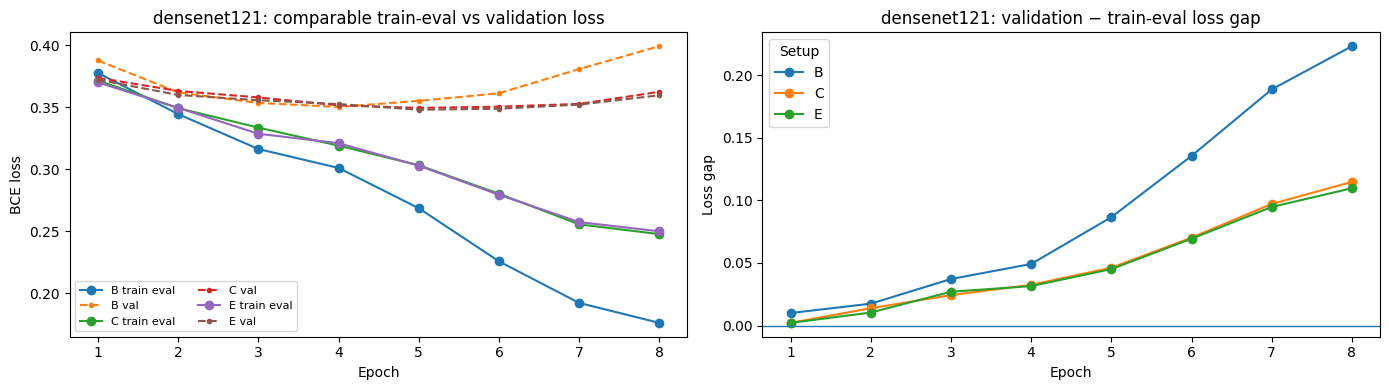

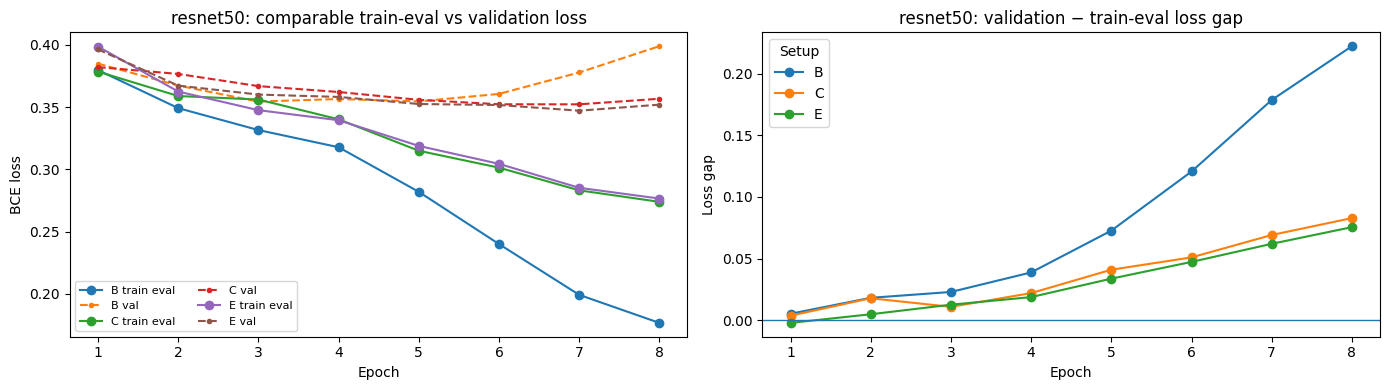

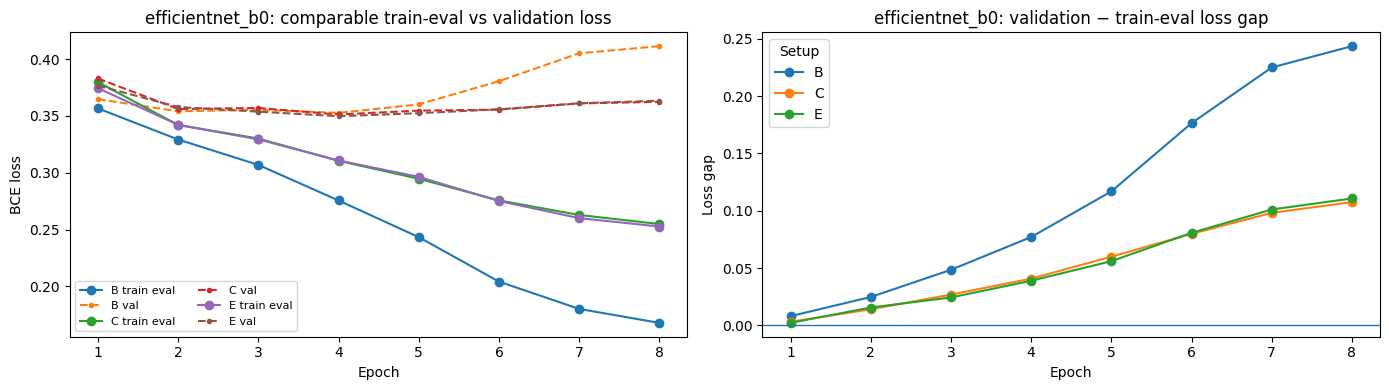

,backbone,setup,best_epoch,val_macro_auroc,val_loss,train_eval_loss,loss_gap,grad_norm_mean,grad_norm_max,frac_clipped,loss_scale
2,densenet121,E,6,0.821380,0.348851,0.279459,0.069392,0.873689,1.590953,0.124642,131072.0
1,densenet121,C,7,0.820863,0.352775,0.255621,0.097153,0.999098,1.857924,0.448424,131072.0
0,densenet121,B,4,0.817734,0.350331,0.301111,0.049220,0.861344,1.271787,0.094556,65536.0
6,efficientnet_b0,B,4,0.816385,0.352642,0.275558,0.077084,0.598856,0.910136,0.000000,131072.0
8,efficientnet_b0,E,5,0.816157,0.352376,0.296336,0.056040,0.545340,1.148286,0.004298,131072.0
7,efficientnet_b0,C,5,0.812624,0.354629,0.294676,0.059953,0.533110,0.900202,0.000000,131072.0
5,resnet50,E,7,0.821036,0.347209,0.285261,0.061948,0.775765,1.126672,0.015759,262144.0
4,resnet50,C,6,0.820752,0.352364,0.301441,0.050923,0.734066,0.979396,0.000000,262144.0
3,resnet50,B,5,0.817901,0.354672,0.282020,0.072652,0.811721,1.147311,0.040115,131072.0


In [9]:
# Reload summaries from disk so this cell also works after a notebook restart.
summary_frames = []
for backbone in BACKBONES:
    for setup in SETUPS:
        p = OUTPUT_DIR / backbone / setup / "run_summary.json"
        if p.exists():
            summary_frames.append(json.loads(p.read_text()))
results_df = pd.DataFrame(summary_frames)
if results_df.empty:
    raise RuntimeError("No completed run summaries found. Run the training cell first.")

display(results_df.pivot(index="setup", columns="backbone", values="best_val_macro_auroc").round(4))

history_frames = []
for backbone in BACKBONES:
    for setup in SETUPS:
        p = OUTPUT_DIR / backbone / setup / "training_log.csv"
        if p.exists():
            h = pd.read_csv(p)
            history_frames.append(h)
history_df = pd.concat(history_frames, ignore_index=True)
history_df.to_csv(OUTPUT_DIR / "combined_training_logs.csv", index=False)

# Plot loss curves and loss gaps separately for each backbone.
for backbone in BACKBONES:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for setup in SETUPS:
        h = history_df[(history_df.backbone == backbone) & (history_df.setup == setup)]
        if h.empty:
            continue
        axes[0].plot(h.epoch, h.train_eval_loss, marker="o", label=f"{setup} train eval")
        axes[0].plot(h.epoch, h.val_loss, marker=".", linestyle="--", label=f"{setup} val")
        axes[1].plot(h.epoch, h.loss_gap, marker="o", label=setup)
    axes[0].set_title(f"{backbone}: comparable train-eval vs validation loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE loss"); axes[0].legend(fontsize=8, ncol=2)
    axes[1].axhline(0, linewidth=1)
    axes[1].set_title(f"{backbone}: validation − train-eval loss gap")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss gap"); axes[1].legend(title="Setup")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{backbone}_loss_and_gap.png", dpi=180, bbox_inches="tight")
    plt.show()

# Summarize the best epoch's loss gap and stability measures for each run.
best_epoch_rows = []
for _, row in results_df.iterrows():
    h = history_df[(history_df.backbone == row.backbone) & (history_df.setup == row.setup)]
    if h.empty:
        continue
    h = h.loc[h.epoch == int(row.best_epoch)].iloc[0]
    best_epoch_rows.append({
        "backbone": row.backbone, "setup": row.setup,
        "best_epoch": int(row.best_epoch),
        "val_macro_auroc": row.best_val_macro_auroc,
        "val_loss": h.val_loss, "train_eval_loss": h.train_eval_loss,
        "loss_gap": h.loss_gap, "grad_norm_mean": h.grad_norm_mean,
        "grad_norm_max": h.grad_norm_max, "frac_clipped": h.frac_clipped,
        "loss_scale": h.loss_scale,
    })
best_epoch_df = pd.DataFrame(best_epoch_rows)
best_epoch_df.to_csv(OUTPUT_DIR / "best_epoch_comparison.csv", index=False)
display(best_epoch_df.sort_values(["backbone", "val_macro_auroc"], ascending=[True, False]))

In [10]:
selected_rows = []
for backbone in BACKBONES:
    subset = results_df[results_df.backbone == backbone].copy()
    if subset.empty:
        raise RuntimeError(f"No completed runs for {backbone}")
    subset = subset.sort_values(
        ["best_val_macro_auroc", "best_val_loss"],
        ascending=[False, True]
    )
    selected_rows.append(subset.iloc[0].to_dict())

selected_df = pd.DataFrame(selected_rows)
selected_df.to_csv(OUTPUT_DIR / "selected_models_by_backbone.csv", index=False)
display(selected_df[["backbone", "setup", "best_epoch", "best_val_macro_auroc", "best_val_loss", "checkpoint"]])

,backbone,setup,best_epoch,best_val_macro_auroc,best_val_loss,checkpoint
0,densenet121,E,6,0.821380,0.348851,/kaggle/working/nih_generalization_experiments...
1,resnet50,E,7,0.821036,0.347209,/kaggle/working/nih_generalization_experiments...
2,efficientnet_b0,B,4,0.816385,0.352642,/kaggle/working/nih_generalization_experiments...


In [11]:

# [Ensembling] Collect logits from the selected checkpoints on validation and NIH test.
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from itertools import combinations

EPS = 1e-3
CV_FOLDS = 5
N_BOOT = 200

def collect_logits(model, loader):
    model.eval()
    logits_all, targets_all = [], []
    with torch.no_grad():
        for images, targets in loader:
            images = images.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(images)
            logits_all.append(logits.float().cpu().numpy())
            targets_all.append(targets.numpy())
    return np.concatenate(logits_all), np.concatenate(targets_all)

val_loader_ensemble = make_loader(final_val, EVAL_BATCH_SIZE, training=False, setup="A", shuffle=False)
test_loader_ensemble = make_loader(test_data, EVAL_BATCH_SIZE, training=False, setup="A", shuffle=False)

val_logits_by_backbone, test_logits_by_backbone = [], []
val_targets = test_targets = None
selected_checkpoint_info = []

for _, selected in selected_df.iterrows():
    model, ckpt = load_checkpoint_model(selected["checkpoint"])
    val_logits, y_val = collect_logits(model, val_loader_ensemble)
    test_logits, y_test = collect_logits(model, test_loader_ensemble)

    if val_targets is None:
        val_targets, test_targets = y_val, y_test
    else:
        assert np.array_equal(val_targets, y_val), "Validation target order differs across models."
        assert np.array_equal(test_targets, y_test), "Test target order differs across models."

    val_logits_by_backbone.append(val_logits)
    test_logits_by_backbone.append(test_logits)
    selected_checkpoint_info.append({
        "backbone": ckpt["backbone"], "setup": ckpt["setup"],
        "epoch": int(ckpt["epoch"]), "checkpoint": str(selected["checkpoint"])
    })
    del model, ckpt
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Z_val = np.stack(val_logits_by_backbone)   # [backbone, validation image, label]
Z_test = np.stack(test_logits_by_backbone) # [backbone, test image, label]
assert Z_val.shape[0] == 3 and Z_test.shape[0] == 3
assert Z_val.shape[2] == len(LABELS)

groups_val = final_val["patient_id"].astype(str).to_numpy()
groups_test = test_data["patient_id"].astype(str).to_numpy()
print("Validation logits:", Z_val.shape, "| NIH test logits:", Z_test.shape)
print("Selected checkpoints:", selected_checkpoint_info)


# Metrics and aggregation helpers.
def sigmoid_np(z):
    z = np.clip(z, -50, 50)
    return 1.0 / (1.0 + np.exp(-z))

def auroc_per_label(scores, targets, min_pos=MIN_POS):
    out = np.full(targets.shape[1], np.nan, dtype=float)
    for j in range(targets.shape[1]):
        y = targets[:, j]
        if (y == 1).sum() < min_pos or (y == 0).sum() < min_pos:
            continue
        out[j] = roc_auc_score(y, scores[:, j])
    return out

def macro_auroc(scores, targets):
    vals = auroc_per_label(scores, targets)
    vals = vals[np.isfinite(vals)]
    return float(vals.mean()) if len(vals) else float("nan")

def rank_normalise(Z):
    # Convert each backbone's logits to per-label empirical ranks in (0, 1].
    out = np.empty(Z.shape, dtype=np.float64)
    for b in range(Z.shape[0]):
        out[b] = rankdata(Z[b], axis=0) / Z.shape[1]
    return out


# Method family 1: unweighted score aggregation.
def predict_unweighted(Z, method):
    P = sigmoid_np(Z)
    if method == "mean_probability":
        return P.mean(axis=0)
    if method == "geometric_mean_probability":
        return np.exp(np.log(np.clip(P, 1e-12, 1.0)).mean(axis=0))
    if method == "median_probability":
        return np.median(P, axis=0)
    if method == "mean_logit":
        return sigmoid_np(Z.mean(axis=0))
    if method == "rank_mean":
        return rank_normalise(Z).mean(axis=0)
    raise ValueError(method)

UNWEIGHTED_METHODS = [
    "mean_probability", "geometric_mean_probability", "median_probability",
    "mean_logit", "rank_mean"
]


# Method family 2: validation-performance-weighted logit aggregation.
def fit_weighted_global(Z, y):
    aucs = np.array([macro_auroc(sigmoid_np(Z[b]), y) for b in range(Z.shape[0])])
    weights = np.clip(np.nan_to_num(aucs, nan=0.5) - 0.5, EPS, None)
    weights /= weights.sum()
    def predict(Z_new):
        return sigmoid_np(np.tensordot(weights, Z_new, axes=(0, 0)))
    predict.info = {"weights": weights.tolist(), "validation_backbone_macro_auroc": aucs.tolist()}
    return predict

def fit_weighted_per_label(Z, y):
    aucs = np.stack([auroc_per_label(sigmoid_np(Z[b]), y) for b in range(Z.shape[0])])
    weights = np.clip(np.nan_to_num(aucs, nan=0.5) - 0.5, EPS, None)
    weights /= weights.sum(axis=0, keepdims=True)
    def predict(Z_new):
        combined_logits = (weights[:, None, :] * Z_new).sum(axis=0)
        return sigmoid_np(combined_logits)
    predict.info = {"weights_by_backbone_and_label": weights.tolist(),
                    "validation_per_label_auroc": aucs.tolist()}
    return predict


# Method family 3: logistic-regression stacking on validation logits.
def _fit_logreg(X, y, C):
    if (y == 1).sum() < 2 or (y == 0).sum() < 2:
        return None
    return LogisticRegression(C=C, max_iter=1000, solver="lbfgs").fit(X, y)

def fit_stack_own(Z, y, C=1.0):
    # One meta-classifier per label; each sees the three backbone logits for that label.
    B, _, L = Z.shape
    fitted = []
    for j in range(L):
        fitted.append(_fit_logreg(Z[:, :, j].T, y[:, j], C))
    def predict(Z_new):
        out = np.empty(Z_new.shape[1:], dtype=float)
        for j, model in enumerate(fitted):
            X = Z_new[:, :, j].T
            out[:, j] = sigmoid_np(X.mean(axis=1)) if model is None else model.predict_proba(X)[:, 1]
        return out
    predict.info = {"C": C, "fitted_labels": [m is not None for m in fitted]}
    return predict

def fit_stack_all(Z, y, C=0.1):
    # Each label-specific meta-classifier sees every backbone × label logit as input.
    B, n, L = Z.shape
    X_fit = Z.transpose(1, 0, 2).reshape(n, B * L)
    fitted = [_fit_logreg(X_fit, y[:, j], C) for j in range(L)]
    def predict(Z_new):
        X = Z_new.transpose(1, 0, 2).reshape(Z_new.shape[1], B * L)
        out = np.empty((Z_new.shape[1], L), dtype=float)
        for j, model in enumerate(fitted):
            out[:, j] = sigmoid_np(Z_new[:, :, j].mean(axis=0)) if model is None else model.predict_proba(X)[:, 1]
        return out
    predict.info = {"C": C, "fitted_labels": [m is not None for m in fitted]}
    return predict


# Patient-grouped cross-fitting: each validation sample is predicted out-of-fold.
def oof_predict_fit_method(Z, y, groups, fit_predict):
    n_splits = min(CV_FOLDS, len(np.unique(groups)))
    if n_splits < 2:
        raise ValueError("Need at least two distinct validation patients for grouped cross-fitting.")
    splitter = GroupKFold(n_splits=n_splits)
    oof = np.zeros((Z.shape[1], y.shape[1]), dtype=float)
    for train_idx, hold_idx in splitter.split(np.arange(Z.shape[1]), groups=groups):
        predictor = fit_predict(Z[:, train_idx], y[train_idx])
        oof[hold_idx] = predictor(Z[:, hold_idx])
    return oof

FIT_METHODS = {
    "weighted_logit_global": fit_weighted_global,
    "weighted_logit_per_label": fit_weighted_per_label,
    "stacking_per_label": fit_stack_own,
    "stacking_all_features": fit_stack_all,
}

# Cross-fitted validation performance is used to compare ensemble approaches.
validation_scores = {}
for method in UNWEIGHTED_METHODS:
    validation_scores[method] = predict_unweighted(Z_val, method)
for name, fit_fn in FIT_METHODS.items():
    validation_scores[name] = oof_predict_fit_method(Z_val, val_targets, groups_val, fit_fn)

validation_comparison = pd.DataFrame([
    {"method": name, "family": (
        "unweighted aggregation" if name in UNWEIGHTED_METHODS else
        "performance-weighted logits" if name.startswith("weighted") else "stacking"
    ), "validation_oof_macro_auroc": macro_auroc(scores, val_targets)}
    for name, scores in validation_scores.items()
]).sort_values("validation_oof_macro_auroc", ascending=False).reset_index(drop=True)

display(validation_comparison)
validation_comparison.to_csv(OUTPUT_DIR / "ensemble_validation_oof_comparison.csv", index=False)


# Refit weighted and stacking predictors on all validation rows, then evaluate once on NIH test.
test_scores = {}
for method in UNWEIGHTED_METHODS:
    test_scores[method] = predict_unweighted(Z_test, method)
for name, fit_fn in FIT_METHODS.items():
    predictor = fit_fn(Z_val, val_targets)
    test_scores[name] = predictor(Z_test)
    (OUTPUT_DIR / f"{name}_fit_info.json").write_text(
        json.dumps(getattr(predictor, "info", {}), indent=2)
    )

# Individual backbone baselines.
for i, backbone in enumerate(BACKBONES):
    test_scores[backbone] = sigmoid_np(Z_test[i])

test_rows = []
for name, scores in test_scores.items():
    per_label = auroc_per_label(scores, test_targets)
    test_rows.append({
        "method": name,
        "family": (
            "individual backbone" if name in BACKBONES else
            "unweighted aggregation" if name in UNWEIGHTED_METHODS else
            "performance-weighted logits" if name.startswith("weighted") else "stacking"
        ),
        "test_macro_auroc": macro_auroc(scores, test_targets),
        **{f"AUROC_{label}": value for label, value in zip(LABELS, per_label)}
    })

test_comparison = pd.DataFrame(test_rows).sort_values("test_macro_auroc", ascending=False)
display(test_comparison)
test_comparison.to_csv(OUTPUT_DIR / "nih_test_ensemble_method_comparison.csv", index=False)


# Patient-level paired bootstrap confidence intervals on the held-out NIH test split.
def patient_bootstrap(score_dict, targets, patient_ids, n_boot=N_BOOT, seed=SEED):
    patient_ids = np.asarray(patient_ids).astype(str)
    unique_patients = np.unique(patient_ids)
    rows_by_patient = [np.flatnonzero(patient_ids == pid) for pid in unique_patients]
    names = list(score_dict)
    rng = np.random.default_rng(seed)
    draws = np.full((n_boot, len(names)), np.nan)
    for b in range(n_boot):
        sampled = rng.integers(0, len(rows_by_patient), size=len(rows_by_patient))
        idx = np.concatenate([rows_by_patient[i] for i in sampled])
        for k, name in enumerate(names):
            draws[b, k] = macro_auroc(score_dict[name][idx], targets[idx])
    return names, draws

bootstrap_names, bootstrap_draws = patient_bootstrap(test_scores, test_targets, groups_test)
bootstrap_rows = []
for i, name in enumerate(bootstrap_names):
    finite = bootstrap_draws[:, i][np.isfinite(bootstrap_draws[:, i])]
    point = macro_auroc(test_scores[name], test_targets)
    lo, hi = np.percentile(finite, [2.5, 97.5]) if len(finite) else (np.nan, np.nan)
    bootstrap_rows.append({"method": name, "test_macro_auroc": point,
                           "ci_2.5": lo, "ci_97.5": hi})
bootstrap_df = pd.DataFrame(bootstrap_rows).sort_values("test_macro_auroc", ascending=False)
display(bootstrap_df)
bootstrap_df.to_csv(OUTPUT_DIR / "nih_test_ensemble_patient_bootstrap.csv", index=False)


# Backbone prediction diversity: mean per-label Spearman/rank correlation on NIH test.
diversity_rows = []
for (i, a), (j, b) in combinations(enumerate(BACKBONES), 2):
    correlations = [
        np.corrcoef(rankdata(Z_test[i, :, label]), rankdata(Z_test[j, :, label]))[0, 1]
        for label in range(len(LABELS))
    ]
    diversity_rows.append({
        "backbone_pair": f"{a} vs {b}",
        "mean_rank_correlation": float(np.nanmean(correlations)),
        **{f"rank_corr_{label}": corr for label, corr in zip(LABELS, correlations)}
    })
diversity_df = pd.DataFrame(diversity_rows)
display(diversity_df)
diversity_df.to_csv(OUTPUT_DIR / "nih_test_backbone_rank_correlation.csv", index=False)


# Save the exact logits, targets and selected checkpoint provenance for reproducibility.
np.savez_compressed(
    OUTPUT_DIR / "nih_ensemble_predictions.npz",
    val_logits=Z_val, val_targets=val_targets,
    test_logits=Z_test, test_targets=test_targets,
    labels=np.asarray(LABELS), backbones=np.asarray(BACKBONES)
)
(OUTPUT_DIR / "nih_ensemble_manifest.json").write_text(json.dumps({
    "dataset": "NIH",
    "labels": LABELS,
    "backbones": BACKBONES,
    "selected_checkpoints": selected_checkpoint_info,
    "ensemble_families": {
        "unweighted_aggregation": UNWEIGHTED_METHODS,
        "performance_weighted_logits": ["weighted_logit_global", "weighted_logit_per_label"],
        "stacking": ["stacking_per_label", "stacking_all_features"]
    },
    "validation_selection": "patient-grouped out-of-fold macro AUROC",
    "test_policy": "official NIH test used only for final reporting; not used for method selection or fitting",
    "bootstrap": {"unit": "patient", "replicates": N_BOOT, "confidence_interval": "percentile 95%"}
}, indent=2))

print("Ensemble artifacts saved under:", OUTPUT_DIR)


NameError: name 'load_checkpoint_model' is not defined

In [ ]:
experiment_manifest = {
    "seed": SEED,
    "dataset": "NIH",
    "labels": LABELS,
    "backbones": BACKBONES,
    "setups": SETUPS,
    "epochs": FINAL_EPOCHS,
    "best_configs": BEST_CONFIGS,
    "stability": {
        "warmup_fraction": WARMUP_FRAC,
        "gradient_clip_norm": GRAD_CLIP_NORM,
        "amp_enabled": USE_AMP,
    },
    "data_sizes": {
        "train": len(final_train), "validation": len(final_val),
        "train_diagnostic": len(train_diagnostic), "official_test": len(test_data),
    },
    "selection_rule": "highest validation macro AUROC; lower validation loss as tie-breaker",
    "ensemble": "unweighted mean of sigmoid probabilities from the selected checkpoint of each backbone",
}
(OUTPUT_DIR / "experiment_manifest.json").write_text(json.dumps(experiment_manifest, indent=2))
print("Saved artifacts under:", OUTPUT_DIR)
print("Top-level files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)